# Notebook for testing and data exploration

### Identifying additional filterable words

In [1]:
# Imports!
import csv
import re # regex model
from collections import Counter

# for data vis
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# for stopwords list
import nltk
from nltk.corpus import stopwords

# to generate data file
import json

nltk.download("stopwords")

ModuleNotFoundError: No module named 'wordcloud'

In [ ]:
# Reading csv file

PATH = "data/us_election_2020_2nd_presidential_debate.csv"

with open(PATH, newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print(len(rows), "turns")
print(Counter(r["speaker"] for r in rows))   # check the exact unique speaker names
print(rows[0].keys())                        # confirm column names

512 turns
Counter({'Donald Trump': 190, 'Kristen Welker': 189, 'Joe Biden': 133})
dict_keys(['speaker', 'minute', 'text'])


In [ ]:
# Clean text
def clean(text):
    text = re.sub(r"\[[^\]]*\]|\([^)]*\)", " ", text)   # drop [crosstalk ...] and (silence)
    text = text.replace("’", "'").replace("…", " ").lower()
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)       # words, keeps don't / i'm

turns = [clean(r["text"]) for r in rows]
tokens = [w for t in turns for w in t]
print(len(tokens), "words")

18289 words


In [ ]:
# Count words NLTK doesn't already treat as stopwords
nltk_stops = set(stopwords.words("english"))
word_counts = Counter(w for w in tokens if w not in nltk_stops)
word_counts.most_common(80)

[('going', 177),
 ('president', 159),
 ('people', 98),
 ('said', 93),
 ('get', 69),
 ('vice', 69),
 ("that's", 63),
 ('say', 57),
 ('know', 55),
 ('would', 54),
 ('want', 53),
 ('one', 52),
 ('biden', 49),
 ('china', 49),
 ('trump', 48),
 ('let', 46),
 ('make', 45),
 ('look', 45),
 ('right', 44),
 ('question', 42),
 ('done', 42),
 ('money', 42),
 ('come', 41),
 ('talk', 39),
 ('years', 39),
 ('move', 37),
 ('joe', 36),
 ('country', 36),
 ('fact', 36),
 ('got', 35),
 ('time', 34),
 ('go', 34),
 ('think', 33),
 ('well', 33),
 ('okay', 31),
 ('way', 30),
 ('million', 29),
 ('like', 29),
 ('us', 29),
 ('thing', 28),
 ('talking', 28),
 ('sure', 28),
 ('two', 28),
 ('new', 28),
 ('plan', 28),
 ('states', 27),
 ('response', 27),
 ("let's", 26),
 ('take', 26),
 ('lot', 26),
 ('need', 26),
 ('good', 25),
 ('first', 25),
 ("what's", 25),
 ('respond', 25),
 ('never', 25),
 ('ask', 24),
 ('give', 24),
 ('made', 24),
 ('back', 24),
 ('number', 24),
 ('families', 23),
 ('russia', 23),
 ('able', 22),

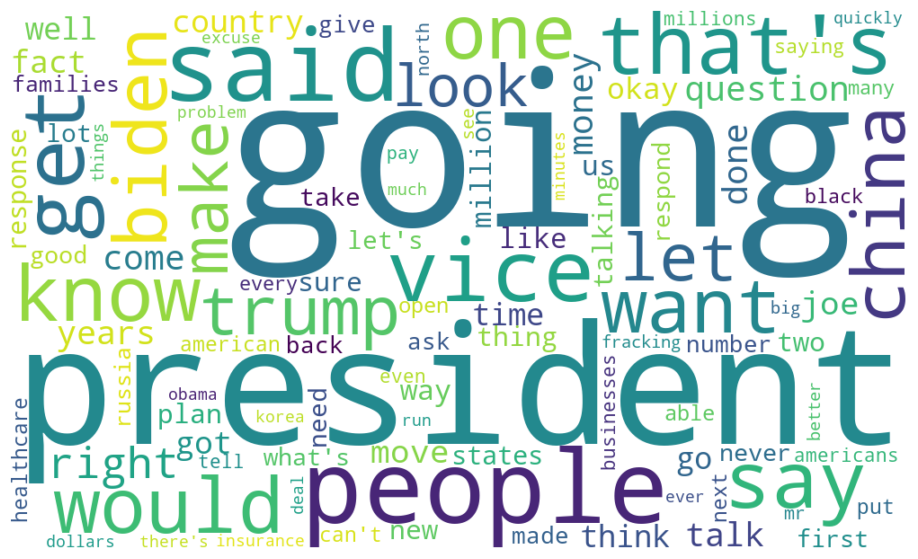

In [ ]:
# Word cloud data visualization
freqs = dict(word_counts.most_common(100))
wc = WordCloud(width=1000, height=600, background_color="white").generate_from_frequencies(freqs)

plt.figure(figsize=(12, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

In [ ]:
# Counting phrases to see if anything is worth highlighting

def norm(w):
    if w.endswith("n't"):
        return "not"
    return re.sub(r"('s|'re|'ve|'ll|'d|'m)$", "", w)

names = {part.lower() for r in rows for part in r["speaker"].split()}
turns = [clean(r["text"]) for r in rows]
turns_norm = [[norm(w) for w in t] for t in turns]
tokens_norm = [w for t in turns_norm for w in t]

def ngrams(words, n):
    return [tuple(words[i:i+n]) for i in range(len(words) - n + 1)]

phrase_skip = nltk_stops | names 
blocklist = set()

def count_phrases(turn_lists, sizes=(2, 3, 4)):
    counts = Counter()
    for t in turn_lists:
        for n in sizes:
            for g in ngrams(t, n):
                if all(w in phrase_skip for w in g):
                    continue
                if " ".join(g) in blocklist:
                    continue
                counts[g] += 1
    return counts

phrase_counts = count_phrases(turns_norm)
print(len(phrase_counts), "distinct phrases")
for g, c in phrase_counts.most_common(60):
    print(f"{c:3d}  {' '.join(g)}")

36141 distinct phrases
163  going to
 69  vice president
 58  we going
 58  we going to
 44  want to
 42  president trump
 40  president biden
 40  vice president biden
 35  let me
 35  to get
 31  talk about
 29  move on
 27  look at
 26  a lot
 25  in fact
 25  he said
 24  i want
 24  all right
 23  talking about
 23  to make
 22  i want to
 22  you know
 22  i think
 22  to move
 21  i going
 21  i going to
 21  able to
 21  the way
 20  make sure
 20  going to do
 19  going to have
 19  your response
 19  to talk
 18  i said
 18  move on to
 17  not going
 17  not going to
 17  you going
 17  you going to
 17  to move on
 16  going to be
 16  lot of
 16  a lot of
 16  excuse me
 15  the world
 15  follow up
 15  not know
 15  to talk about
 15  millions of
 15  north korea
 14  united states
 14  to respond
 14  need to
 14  going to move
 13  two minutes
 13  the united
 13  the united states
 13  be able
 13  to go
 13  i not know


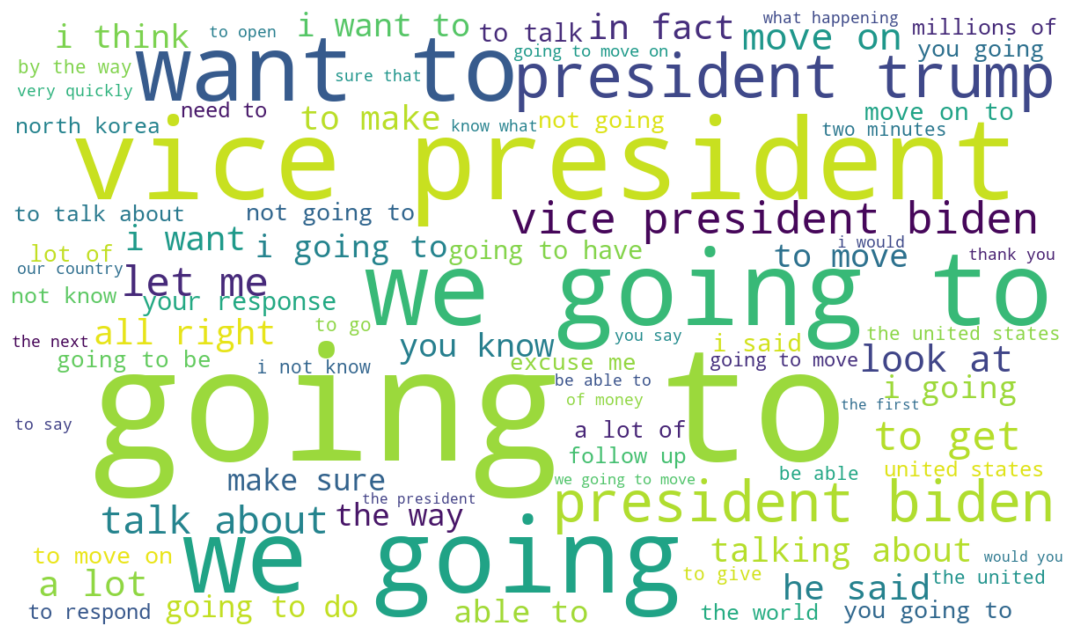

In [ ]:
MIN_SHOWN = 2
TOP_N = 80

freqs = {" ".join(g): c for g, c in phrase_counts.most_common(300) if c >= MIN_SHOWN}
freqs = dict(list(freqs.items())[:TOP_N])

wc = WordCloud(width=1200, height=700, background_color="white",
               prefer_horizontal=1.0, colormap='viridis').generate_from_frequencies(freqs)

plt.figure(figsize=(14, 8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

In [ ]:
# Filtering phrases
keep = {"we", "they", "will"}  # NLTK words to keep inside phrases
scaffolding = {"going", "know", "think", "said"}  # filler from the cloud
titles = {"president", "vice", "mr", "mister"}

phrase_skip = (nltk_stops - keep) | names | titles | scaffolding
blocklist = {"make sure", "sure we"}  # any phrase containing one of these is dropped

def blocked(phrase):
    padded = f" {phrase} "
    return any(f" {b} " in padded for b in blocklist)

def count_phrases(turn_lists, sizes=(2, 3, 4)):
    counts = Counter()
    for t in turn_lists:
        for n in sizes:
            for g in ngrams(t, n):
                if g[0] in phrase_skip or g[-1] in phrase_skip:   # trim phrases that start or end with a skip word
                    continue
                if blocked(" ".join(g)):
                    continue
                counts[g] += 1
    return counts

phrase_counts = count_phrases(turns_norm)
print(len(phrase_counts), "distinct phrases")
for g, c in phrase_counts.most_common(60):
    print(f"{c:3d}  {' '.join(g)}")

8439 distinct phrases
 15  north korea
 14  united states
 13  two minutes
 12  we going to move
 11  let talk
 11  let me ask
 10  wall street
 10  come back
  9  minutes uninterrupted
  9  two minutes uninterrupted
  9  american people
  9  new york
  9  next section
  8  lot of money
  8  number one
  8  we got
  8  right let
  8  let move
  8  pre existing
  8  eight years
  8  minimum wage
  8  abraham lincoln
  8  oil industry
  7  million people
  7  take a look
  7  want to talk
  7  four years
  7  we talking
  7  years ago
  7  social security
  7  climate change
  7  final question
  6  we in a situation
  6  let me follow
  6  they need
  6  time we
  6  three years
  6  we going to talk
  6  good relationship
  6  health insurance
  6  socialized medicine
  6  they want
  6  small businesses
  6  built the cages
  5  every single
  5  we have to open
  5  nancy pelosi
  5  okay let
  5  look at what happening
  5  one thing
  5  number two
  5  millions of dollars
  5  mak

In [ ]:
MIN_WORD = 8

manual_skip = set()
word_skip = nltk_stops | names | titles | scaffolding | manual_skip

word_counts = Counter(w for w in tokens_norm if w not in word_skip)

for w, c in word_counts.most_common(40):
    print(f"{c:4d}  {w}")

 103  people
  72  let
  69  get
  57  say
  56  would
  54  china
  53  want
  52  one
  45  make
  45  look
  44  right
  43  money
  42  question
  42  done
  41  come
  39  talk
  39  years
  37  move
  36  country
  36  fact
  35  got
  34  time
  34  go
  33  well
  31  okay
  30  way
  29  million
  29  like
  29  us
  28  thing
  28  talking
  28  sure
  28  two
  28  new
  28  plan
  27  states
  27  response
  26  take
  26  lot
  26  need


In [ ]:
# Combines filtered phrase and word lists 
MIN_PHRASE = 3

combined = (
    [(" ".join(g), c, "phrase") for g, c in phrase_counts.items() if c >= MIN_PHRASE]
    + [(w, c, "word") for w, c in word_counts.items() if c >= MIN_WORD]
)
combined.sort(key=lambda x: (-x[1], x[0]))     # highest count first, ties alphabetical

print(len(combined), "entries")
for i, (text, count, kind) in enumerate(combined, 1):
    print(f"{i:3d}. {count:3d}  {text}  [{kind}]")

448 entries
  1. 103  people  [word]
  2.  72  let  [word]
  3.  69  get  [word]
  4.  57  say  [word]
  5.  56  would  [word]
  6.  54  china  [word]
  7.  53  want  [word]
  8.  52  one  [word]
  9.  45  look  [word]
 10.  45  make  [word]
 11.  44  right  [word]
 12.  43  money  [word]
 13.  42  done  [word]
 14.  42  question  [word]
 15.  41  come  [word]
 16.  39  talk  [word]
 17.  39  years  [word]
 18.  37  move  [word]
 19.  36  country  [word]
 20.  36  fact  [word]
 21.  35  got  [word]
 22.  34  go  [word]
 23.  34  time  [word]
 24.  33  well  [word]
 25.  31  okay  [word]
 26.  30  way  [word]
 27.  29  like  [word]
 28.  29  million  [word]
 29.  29  us  [word]
 30.  28  new  [word]
 31.  28  plan  [word]
 32.  28  sure  [word]
 33.  28  talking  [word]
 34.  28  thing  [word]
 35.  28  two  [word]
 36.  27  response  [word]
 37.  27  states  [word]
 38.  26  lot  [word]
 39.  26  need  [word]
 40.  26  take  [word]
 41.  25  first  [word]
 42.  25  good  [word]
 43.  2

In [ ]:
# Determining how many of each to keep or consider "top"
# All of these will be amplified

TOP_WORDS = 30
TOP_PHRASES = 30

top_words = word_counts.most_common(TOP_WORDS)
top_phrases = [(" ".join(g), c) for g, c in phrase_counts.most_common(TOP_PHRASES)]

print("WORDS")
for i, (w, c) in enumerate(top_words, 1):
    print(f"{i:3d}. {c:4d}  {w}")

print("\nPHRASES")
for i, (p, c) in enumerate(top_phrases, 1):
    print(f"{i:3d}. {c:4d}  {p}")

WORDS
  1.  103  people
  2.   72  let
  3.   69  get
  4.   57  say
  5.   56  would
  6.   54  china
  7.   53  want
  8.   52  one
  9.   45  make
 10.   45  look
 11.   44  right
 12.   43  money
 13.   42  question
 14.   42  done
 15.   41  come
 16.   39  talk
 17.   39  years
 18.   37  move
 19.   36  country
 20.   36  fact
 21.   35  got
 22.   34  time
 23.   34  go
 24.   33  well
 25.   31  okay
 26.   30  way
 27.   29  million
 28.   29  like
 29.   29  us
 30.   28  thing

PHRASES
  1.   15  north korea
  2.   14  united states
  3.   13  two minutes
  4.   12  we going to move
  5.   11  let talk
  6.   11  let me ask
  7.   10  wall street
  8.   10  come back
  9.    9  minutes uninterrupted
 10.    9  two minutes uninterrupted
 11.    9  american people
 12.    9  new york
 13.    9  next section
 14.    8  lot of money
 15.    8  number one
 16.    8  we got
 17.    8  right let
 18.    8  let move
 19.    8  pre existing
 20.    8  eight years
 21.    8  minimum 

In [ ]:
# Issue detected! We have phrases within each other!
RATIO = 1.25  # a shorter phrase is dropped if it adds < 25% over the longer one containing it

def contains(big, small):
    return any(big[i:i+len(small)] == small for i in range(len(big) - len(small) + 1))

def collapse(counts, ratio=RATIO):
    kept = {}
    for g, c in sorted(counts.items(), key=lambda x: -len(x[0])):   # longest first
        redundant = any(len(big) > len(g) and contains(big, g) and c <= bc * ratio
                        for big, bc in kept.items())
        if not redundant:
            kept[g] = c
    return kept

candidates = {g: c for g, c in phrase_counts.items() if c >= MIN_PHRASE}
phrase_counts_collapsed = collapse(candidates)
print(len(candidates), "->", len(phrase_counts_collapsed), "phrases after collapsing")

top_words = word_counts.most_common(TOP_WORDS)
top_phrases = [(" ".join(g), c) for g, c in
               sorted(phrase_counts_collapsed.items(), key=lambda x: (-x[1], x[0]))[:TOP_PHRASES]]

print("\nWORDS")
for i, (w, c) in enumerate(top_words, 1):
    print(f"{i:3d}. {c:4d}  {w}")

print("\nPHRASES")
for i, (p, c) in enumerate(top_phrases, 1):
    print(f"{i:3d}. {c:4d}  {p}")

215 -> 195 phrases after collapsing

WORDS
  1.  103  people
  2.   72  let
  3.   69  get
  4.   57  say
  5.   56  would
  6.   54  china
  7.   53  want
  8.   52  one
  9.   45  make
 10.   45  look
 11.   44  right
 12.   43  money
 13.   42  question
 14.   42  done
 15.   41  come
 16.   39  talk
 17.   39  years
 18.   37  move
 19.   36  country
 20.   36  fact
 21.   35  got
 22.   34  time
 23.   34  go
 24.   33  well
 25.   31  okay
 26.   30  way
 27.   29  million
 28.   29  like
 29.   29  us
 30.   28  thing

PHRASES
  1.   15  north korea
  2.   14  united states
  3.   13  two minutes
  4.   12  we going to move
  5.   11  let me ask
  6.   11  let talk
  7.   10  come back
  8.   10  wall street
  9.    9  american people
 10.    9  new york
 11.    9  next section
 12.    9  two minutes uninterrupted
 13.    8  abraham lincoln
 14.    8  eight years
 15.    8  let move
 16.    8  lot of money
 17.    8  minimum wage
 18.    8  number one
 19.    8  oil industry
 20

In [ ]:
# Number of unique words to calibrate how many words/phrases is sensible

total_words = len(tokens_norm)
unique_all = len(set(tokens_norm))

kept = [w for w in tokens_norm if w not in word_skip]
unique_kept = len(set(kept))

print(f"total words:               {total_words}")
print(f"unique words (all):        {unique_all}")
print(f"words after filtering:     {len(kept)}")
print(f"unique words (filtered):   {unique_kept}")
print(f"unique / total (variety):  {unique_all / total_words:.1%}")

total words:               18289
unique words (all):        2046
words after filtering:     7501
unique words (filtered):   1917
unique / total (variety):  11.2%


In [ ]:
# Computing percent of words that will be louder

word_set = {w for w, _ in top_words}
phrase_list = [tuple(p.split()) for p, _ in top_phrases]

total = 0
hit_words = hit_phrases = hit_either = 0

for t in turns_norm:
    in_word = [w in word_set for w in t]
    in_phrase = [False] * len(t)
    for ph in phrase_list:
        n = len(ph)
        for i in range(len(t) - n + 1):
            if tuple(t[i:i+n]) == ph:
                for j in range(i, i + n):
                    in_phrase[j] = True
    total += len(t)
    hit_words += sum(in_word)
    hit_phrases += sum(in_phrase)
    hit_either += sum(a or b for a, b in zip(in_word, in_phrase))

print(f"total words:            {total}")
print(f"percent words louder:        {hit_either}  ({hit_either/total:.1%})")

total words:            18289
percent words louder:        1724  (9.4%)


In [ ]:
# Take processed data and put into a JSON file to be used in our program!!
filtered_data = {
    "source": "us_election_2020_2nd_presidential_debate.csv",
    "settings": {
        "top_words": TOP_WORDS,
        "top_phrases": TOP_PHRASES,
        "min_phrase": MIN_PHRASE,
        "collapse_ratio": RATIO,
    },
    "words":   [{"text": w, "count": c} for w, c in top_words],
    "phrases": [{"text": p, "n": len(p.split()), "count": c} for p, c in top_phrases],
}

with open("filtered_data.json", "w", encoding="utf-8") as f:
    json.dump(filtered_data, f, indent=2)

print(f"saved {len(filtered_data['words'])} words and {len(filtered_data['phrases'])} phrases")

saved 30 words and 30 phrases
